In [2]:
%cd "C:\Users\11584\Desktop\OMGroup\ESE023\Assignment_04"
##设置路径

C:\Users\11584\Desktop\OMGroup\ESE023\Assignment_04


In [3]:
%pwd

'C:\\Users\\11584\\Desktop\\OMGroup\\ESE023\\Assignment_04'

In [4]:
# 导入包
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

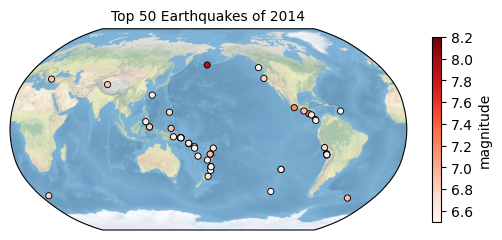

In [5]:
## 1. 复现
# 提取2014年的，按震级取前50条
data = pd.read_csv("usgs_earthquakes.csv")
top50 = data.nlargest(50, "mag")

# 绘制以太平洋为中心的全球地图
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ax.set_global()  # 显示全球范围
ax.stock_img()   # 添加 Cartopy 自带的地形底图

# 按经纬度定位，用 mag 控制圆点颜色
points = ax.scatter(
    top50["longitude"], top50["latitude"],
    c=top50["mag"],
    cmap="Reds",                  
    s=20,                         
    edgecolors="black",            # 添加黑色边缘
    linewidths=0.65,
    transform=ccrs.PlateCarree(),  
)

ax.set_title("Top 50 Earthquakes of 2014", fontsize = 10)

# 在地图右侧放置竖直色标
colorbar = plt.colorbar(points, ax=ax, 
                        label="magnitude",
                       shrink = 0.5,
                       aspect = 20)

colorbar.set_label("magnitude", fontsize=10)
colorbar.set_ticks([6.6, 6.8, 7.0, 7.2, 7.4, 7.6, 7.8, 8.0, 8.2])
#保存到本地
plt.savefig("global_earthquakes.png")
plt.show()

In [10]:
## 2  dataset exploration
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.patches import Rectangle

# ../ 表示返回上一级目录，再进入 Assignment_03
ds = xr.open_dataset("../Assignment_03/GLDAS_VIC10_M_2.0_2000_2013.nc")

#按月份求多年平均，保留空间维度
snow = ds["Qsm_acc"].mean("time")

#提取喜马拉雅山脉区域空间
region = snow.sel(lon=slice(70, 105), lat=slice(25, 45))
print(ds["Qsm_acc"])

<xarray.DataArray 'Qsm_acc' (time: 168, lat: 150, lon: 360)> Size: 36MB
array([[[nan, nan, ..., nan, nan],
        [nan, nan, ..., nan, nan],
        ...,
        [nan, nan, ..., nan, nan],
        [nan, nan, ..., nan, nan]],

       [[nan, nan, ..., nan, nan],
        [nan, nan, ..., nan, nan],
        ...,
        [nan, nan, ..., nan, nan],
        [nan, nan, ..., nan, nan]],

       ...,

       [[nan, nan, ..., nan, nan],
        [nan, nan, ..., nan, nan],
        ...,
        [nan, nan, ..., nan, nan],
        [nan, nan, ..., nan, nan]],

       [[nan, nan, ..., nan, nan],
        [nan, nan, ..., nan, nan],
        ...,
        [nan, nan, ..., nan, nan],
        [nan, nan, ..., nan, nan]]], shape=(168, 150, 360), dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 1kB 2000-01-01 2000-02-01 ... 2013-12-01
  * lat      (lat) float32 600B -59.5 -58.5 -57.5 -56.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float32 1kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
Attribu

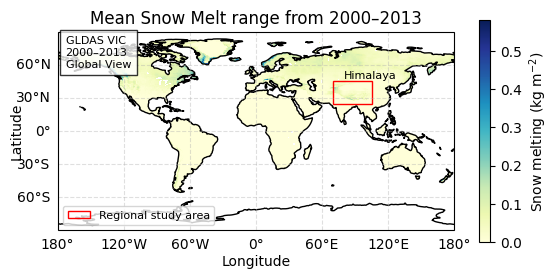

In [17]:
## 2.1 global map
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_global()

#pcolormesh将每个经纬度网格的数值绘制成颜色
image = ax.pcolormesh(
    snow.lon, snow.lat, snow,
    cmap="YlGnBu",
    transform=ccrs.PlateCarree(),
)

ax.coastlines()  #添加海岸线

#添加经纬网和刻度标签，关闭上方及右侧标签
grid = ax.gridlines(draw_labels=True, linestyle="--", alpha=0.4)
grid.top_labels = False
grid.right_labels = False

#Gridliner 的刻度标签独立绘制，这里用轴坐标放置经纬度名称
ax.text(0.5, -0.18, "Longitude", transform=ax.transAxes, ha="center")
ax.text(-0.12, 0.5, "Latitude", transform=ax.transAxes,
        rotation=90, va="center")

#Rectangle的参数依次是左下角坐标、宽度、高度
box = Rectangle(
    (70, 25), 35, 20,
    fill=False, edgecolor="red",
    transform=ccrs.PlateCarree(),
    label="Regional study area",
)
ax.add_patch(box)
ax.legend(loc="lower left", fontsize=8)

#在经纬度位置添加地理注释
ax.text(80, 48, "Himalaya",
        transform=ccrs.PlateCarree(), fontsize=8)

#使用轴坐标定位文本框，(0, 0) 为左下角区域
ax.text(
    0.02, 0.98,
    "GLDAS VIC\n2000–2013\nGlobal View",
    transform=ax.transAxes, va="top", fontsize=8,
    bbox=dict(facecolor="white", alpha=0.8),
)

ax.set_title("Mean Snow Melt range from 2000–2013")
plt.colorbar(image, ax=ax, shrink=0.6, label="Snow melting (kg m$^{-2}$)")
#保存图片
plt.savefig("snow_melt_global.png", dpi=300, bbox_inches="tight")
plt.show()

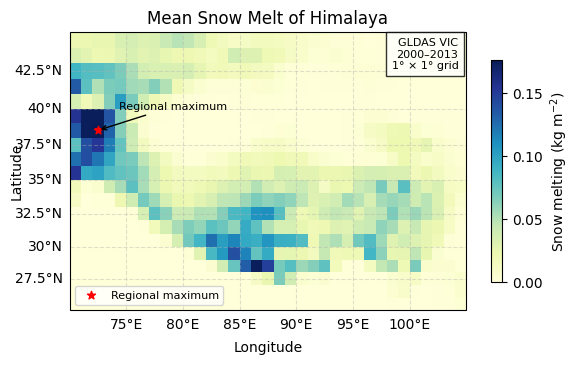

In [16]:
## 2.2 region map
# 找到区域内数值最大的网格
peak = region.where(region == region.max(), drop=True)
peak_lon = peak.lon.values[0]
peak_lat = peak.lat.values[0]

ax = plt.axes(projection=ccrs.Mercator())
ax.set_extent([70, 105, 25, 45], crs=ccrs.PlateCarree())

#二维网格绘图
image = ax.pcolormesh(
    region.lon, region.lat, region,
    cmap="YlGnBu",
    transform=ccrs.PlateCarree(),
)

#ax.coastlines()

grid = ax.gridlines(draw_labels=True, linestyle="--", alpha=0.4)
grid.top_labels = False
grid.right_labels = False

#地图投影按照经纬度进行转换
ax.text(0.5, -0.15, "Longitude", transform=ax.transAxes, ha="center")
ax.text(-0.15, 0.5, "Latitude", transform=ax.transAxes,
        rotation=90, va="center")

#用两种方式标明区域最大值的位置，分别是添加图例以及标注箭头
ax.scatter(
    peak_lon, peak_lat, color="red", marker="*",
    transform=ccrs.PlateCarree(), label="Regional maximum",
)
ax.legend(loc="lower left", fontsize=8)

#添加带箭头的注释，xy 使用经纬度，xytext 使用偏移距离
ax.annotate(
    "Regional maximum",
    xy=(peak_lon, peak_lat),
    xycoords=ccrs.PlateCarree()._as_mpl_transform(ax),
    xytext=(15, 15), textcoords="offset points",
    arrowprops=dict(arrowstyle="->"), fontsize=8,
)

ax.text(
    0.98, 0.98,
    "GLDAS VIC\n2000–2013\n1° × 1° grid",
    transform=ax.transAxes, ha="right", va="top", fontsize=8,
    bbox=dict(facecolor="white", alpha=0.8),
)

ax.set_title("Mean Snow Melt of Himalaya")
plt.colorbar(image, ax=ax, shrink=0.6, label="Snow melting (kg m$^{-2}$)")
#保存图片
plt.savefig("snow_melt_regional.png", dpi=300, bbox_inches="tight")
plt.show()

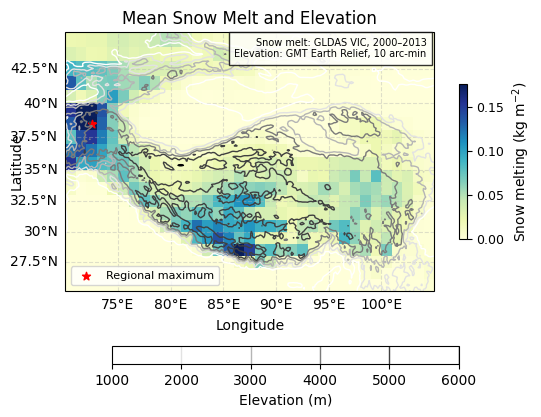

In [31]:
# elevation plot
from matplotlib.lines import Line2D
dem = xr.open_dataset("earth_relief_10m_g.grd")

# GMT 地形文件通常以z存储海拔，单位为米
# 排序后再截取，保证切片方向从小到大
height = dem["z"].sortby("lat").sortby("lon")
height = height.sel(lon=slice(70, 105), lat=slice(25, 45))

ax = plt.axes(projection=ccrs.Mercator())
ax.set_extent([70, 105, 25, 45], crs=ccrs.PlateCarree())

image = ax.pcolormesh(
    region.lon, region.lat, region,
    cmap="YlGnBu",
    transform=ccrs.PlateCarree(),
)

# 添加经纬网和经纬度刻度
grid = ax.gridlines(draw_labels=True, linestyle="--", alpha=0.4)
grid.top_labels = False
grid.right_labels = False

ax.text(0.5, -0.15, "Longitude", transform=ax.transAxes, ha="center")
ax.text(-0.15, 0.5, "Latitude", transform=ax.transAxes,
        rotation=90, va="center")
ax.scatter(
    peak_lon, peak_lat, color="red", marker="*",
    transform=ccrs.PlateCarree(), label="Regional maximum",
)
ax.legend(loc="lower left", fontsize=8)

# 不同海拔使用不同颜色，线条加粗以便辨认
contours = ax.contour(
    height.lon, height.lat, height,
    levels=[1000, 2000, 3000, 4000, 5000, 6000],
    cmap="Greys",             # 从黄色逐渐变为红色
    linewidths=1,
    transform=ccrs.PlateCarree(),
)


# 添加海拔色标，原来的融雪色标也保留
elevation_bar = plt.colorbar(
    contours, ax=ax,
    orientation="horizontal",
    pad=0.15, shrink=0.7,
)
elevation_bar.set_label("Elevation (m)")

colorbar = plt.colorbar(image, ax=ax, shrink=0.6)
colorbar.set_label("Snow melting (kg m$^{-2}$)", fontsize=10)
colorbar.ax.tick_params(labelsize=9)

ax.text(
    0.98, 0.98,
    "Snow melt: GLDAS VIC, 2000–2013\n"
    "Elevation: GMT Earth Relief, 10 arc-min",
    transform=ax.transAxes,
    ha="right", va="top", fontsize=7,
    bbox=dict(facecolor="white", alpha=0.8),
)
ax.set_title("Mean Snow Melt and Elevation", fontsize=12)


plt.savefig("snow_melt_elevation.png", dpi=300, bbox_inches="tight")
plt.show()